<small>Dataset: loan.xlsx</small>

# Q14. Loan Approval Decision Tree

Train a decision tree and explain its predictions using a plotted tree.


## Question from Classroom

Loan Approval Prediction Using Decision Tree 
Problem statement: Predict whether a loan application should be approved using applicant 
information. 
Tasks to be performed: 
1. Load a labeled loan approval dataset. 
2. Identify the target variable and relevant applicant features. 
3. Handle missing values and encode categorical variables. 
4. Split the dataset into training and testing sets. 
5. Train a Decision Tree classifier using Gini impurity or entropy. 
6. Visualize the tree and predict approval for test records. 
7. Display accuracy, precision, recall, F1-score and the confusion matrix.


## Understand before coding

Read and inspect -> choose X/y -> stratified split -> training-only imputation -> train a depth-limited tree -> print classification metrics and visualize.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl
```


**Code layout:** 7 listed tasks → 7 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Load a labeled loan approval dataset.

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.tree import DecisionTreeClassifier, plot_tree
df = pd.read_excel("data/loan.xlsx")
df.columns = df.columns.str.strip()
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
df = df.dropna(subset=["Loan_Status"])

print("Rows and columns:", df.shape)
print(df.head())
df.info()
print("Missing values:\n", df.isna().sum())
print("Summary:\n", df.describe(include="all").T)


Rows and columns: (207, 13)
    Loan_ID  Gender Married  ...  Credit_History Property_Area Loan_Status
0  LP002314  Female      No  ...             1.0         Rural           Y
1  LP002315    Male     Yes  ...             0.0     Semiurban           N
2  LP002317    Male     Yes  ...             0.0         Rural           N
3  LP002318  Female      No  ...             1.0     Semiurban           N
4  LP002319    Male     Yes  ...             NaN         Urban           Y

[5 rows x 13 columns]
<class 'pandas.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            207 non-null    str    
 1   Gender             200 non-null    str    
 2   Married            206 non-null    str    
 3   Dependents         203 non-null    object 
 4   Education          207 non-null    str    
 5   Self_Employed      197 non-null    str    
 6   ApplicantIncome 

## Task 2. Identify the target variable and relevant applicant features.

This block implements the task above. Variables from earlier blocks are reused.


In [2]:
target="Loan_Status"
features=["ApplicantIncome","CoapplicantIncome","LoanAmount","Loan_Amount_Term","Credit_History","Gender","Married","Education"]
print("Target:",target,"Features:",features)


Target: Loan_Status Features: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Gender', 'Married', 'Education']


## Task 3. Handle missing values and encode categorical variables.

This block implements the task above. Variables from earlier blocks are reused.


In [3]:
df["Gender"] = df["Gender"].map({"Male":1,"Female":0})
df["Married"] = df["Married"].map({"Yes":1,"No":0})
df["Education"] = df["Education"].map({"Graduate":1,"Not Graduate":0})
features = ["ApplicantIncome","CoapplicantIncome","LoanAmount","Loan_Amount_Term",
            "Credit_History","Gender","Married","Education"]
X = df[features]
y = df["Loan_Status"]
print("Class counts:\n",y.value_counts())

def fill_missing(training,testing):
    medians=training.median()
    return training.fillna(medians),testing.fillna(medians)
print("Missing numeric values will use training medians after the split.")


Class counts:
 Loan_Status
Y    140
N     67
Name: count, dtype: int64
Missing numeric values will use training medians after the split.


## Task 4. Split the dataset into training and testing sets.

This block implements the task above. Variables from earlier blocks are reused.


In [4]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
X_train,X_test=fill_missing(X_train,X_test)


## Task 5. Train a Decision Tree classifier using Gini impurity or entropy.

This block implements the task above. Variables from earlier blocks are reused.


In [5]:
model=DecisionTreeClassifier(criterion="gini",max_depth=4,random_state=42)
model.fit(X_train,y_train)


## Task 6. Visualize the tree and predict approval for test records.

This block implements the task above. Variables from earlier blocks are reused.


Predicted loan labels: ['Y' 'Y' 'Y' 'Y' 'N' 'Y' 'Y' 'Y' 'N' 'Y']


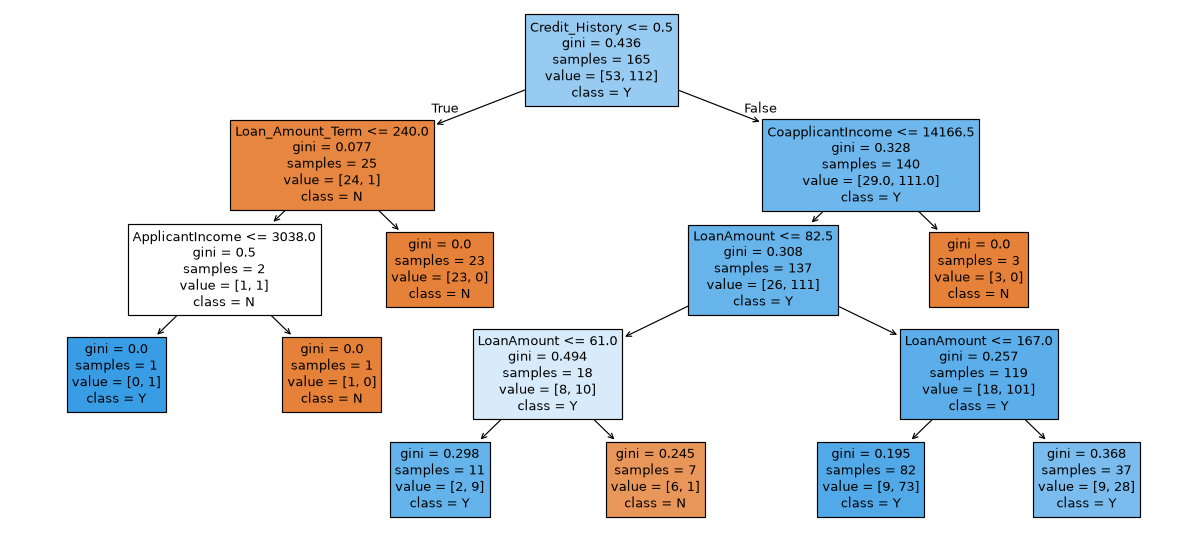

In [6]:
plt.figure(figsize=(18,8))
plot_tree(model,feature_names=X_train.columns.tolist(),class_names=[str(c) for c in model.classes_],filled=True)
plt.show()
prediction=model.predict(X_test)
print("Predicted loan labels:",prediction[:10])


## Task 7. Display accuracy, precision, recall, F1-score and the confusion matrix.

This block implements the task above. Variables from earlier blocks are reused.


In [7]:
print("Accuracy:",round(accuracy_score(y_test,prediction),4))
print("Class order:",model.classes_)
print("Confusion matrix:\n",confusion_matrix(y_test,prediction,labels=model.classes_))
print(classification_report(y_test,prediction,zero_division=0))


Accuracy: 0.7619
Class order: ['N' 'Y']
Confusion matrix:
 [[ 8  6]
 [ 4 24]]
              precision    recall  f1-score   support

           N       0.67      0.57      0.62        14
           Y       0.80      0.86      0.83        28

    accuracy                           0.76        42
   macro avg       0.73      0.71      0.72        42
weighted avg       0.76      0.76      0.76        42



## Viva preparation guide



**1. What are X and y?**

X contains the predictor columns; y contains the target we want to predict. X is a 2D table and y is a 1D series.

**2. Why split training and testing data?**

Fit using the training examples. Evaluate on separate examples to estimate how well the model generalizes.

**3. What do fit() and predict() mean?**

fit() learns parameters from training examples. predict() applies the learned model to new feature rows.

**4. Why random_state=42?**

It makes random splits or model choices reproducible. The number 42 has no special mathematical meaning.

**5. What is data leakage?**

Information unavailable for a real prediction accidentally influences training. Examples: including the answer in X or fitting a scaler on test data. Fit learned preprocessing only on training data.

**6. What is overfitting?**

The model learns training-specific details/noise and does worse on unseen data. Control complexity and use validation or cross-validation.

**7. What is a hyperparameter?**

A setting chosen outside model fitting, such as max_depth, K or the number of trees. Choose it using training validation, not by repeatedly optimizing the final test result.

**8. How do I fix FileNotFoundError or KeyError?**

Open Jupyter in the praceice folder, keep data/ beside this notebook, and print df.columns.tolist() to check exact column names. Do not change X and y row counts separately.

**9. What does the confusion matrix contain?**

Rows are actual classes and columns are predicted classes, in the printed label order. For binary labels [0,1], it is [[TN,FP],[FN,TP]].

**10. Define accuracy, precision, recall and F1.**

Accuracy=(TP+TN)/N. Precision=TP/(TP+FP). Recall=TP/(TP+FN). F1=2PR/(P+R). classification_report prints per-class values and macro/weighted averages. zero_division=0 handles an undefined score.

**11. Why can accuracy be misleading?**

If most examples belong to one class, always predicting that class may give high accuracy. Inspect minority-class recall, precision, F1 and the confusion matrix.

**12. Why stratify=y?**

It approximately preserves class proportions in training and test splits. Each class needs enough examples.

**13. How does a decision tree work?**

It asks feature-threshold questions, sending records down branches until a leaf predicts a class.

**14. Gini impurity?**

Gini=1-sum(p_i^2). It is zero for a pure node. A split is chosen to reduce weighted child impurity.

**15. Entropy?**

Entropy=-sum(p_i*log2(p_i)), with zero-probability terms treated as zero. Information gain is parent entropy minus weighted child entropy.

**16. Why limit max_depth?**

Very deep trees can memorize noise. Limiting depth often reduces overfitting and makes the plotted tree easier to explain.

**17. Does a tree need scaling?**

Usually no. It compares thresholds; it does not calculate Euclidean distances.

**18. What are leaves and feature importance?**

Leaves hold final class decisions. Impurity-based feature importance measures accumulated split improvements; it is not causation and can be biased.

**19. Complexity?**

For a reasonably balanced tree, training is often roughly O(p*n*log n), depending on implementation; prediction follows one path of length equal to tree depth. Deep worst cases can cost more.

**20. What is the target?**

Loan_Status: Y or N. The selected applicant/income/credit columns are inputs; Loan_ID is excluded.

**21. How are categories handled?**

Fixed binary mappings encode Gender, Married and Education. Training medians fill missing feature values after the split. This example selects relevant columns so mixed-format Dependents is not required.


### Task-to-code map

- **Block 1:** Load a labeled loan approval dataset.
- **Block 2:** Identify the target variable and relevant applicant features.
- **Block 3:** Handle missing values and encode categorical variables.
- **Block 4:** Split the dataset into training and testing sets.
- **Block 5:** Train a Decision Tree classifier using Gini impurity or entropy.
- **Block 6:** Visualize the tree and predict approval for test records.
- **Block 7:** Display accuracy, precision, recall, F1-score and the confusion matrix.
